# Stock Market Performance, Risk & Investment Analysis

### Financial Analytics Project | Python

**Author:** Faith Fairley  
**University:** Kean University  
**Degree:** B.S. Business Analytics and Data Science (Finance)

## Project Overview

This project examines the historical stock market performance of five publicly traded companies across the technology, financial services, and consumer sectors.

Using Python and financial data analysis, the project evaluates stock returns, investment risk, price movements, and volatility to identify differences in historical investment performance.

## Research Objectives

- Compare the historical performance of five publicly traded companies.
- Calculate daily and annualized stock returns.
- Measure investment risk through historical volatility.
- Identify patterns in stock price movements.
- Translate financial data into meaningful analytical insights.

## 1. Importing Libraries

The following Python libraries are used to collect, manipulate, analyze, and visualize financial market data.

- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical calculations and financial metrics.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualizations.
- **yfinance:** Historical stock market data retrieval.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f'{x:,.4f}')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Company Selection and Research Period

Five publicly traded companies were selected for this analysis to examine stock market performance across different industries, including technology, financial services, and consumer goods.

The selected companies are:

- **Apple (AAPL):** Consumer technology
- **Microsoft (MSFT):** Software and technology
- **NVIDIA (NVDA):** Semiconductors and AI technology
- **JPMorgan Chase (JPM):** Financial services and banking
- **Amazon (AMZN):** E-commerce and cloud computing

The research period covers January 2021 through December 2025. This five-year period provides a consistent historical timeframe for comparing stock prices, investment returns, and market volatility.

In [3]:

# Define the companies we want to analyze

tickers = {
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "NVIDIA": "NVDA",
    "JPMorgan Chase": "JPM",
    "Amazon": "AMZN"
}

# Set the research period
start_date = "2021-01-01"
end_date = "2026-01-01"

print("Companies selected:")
for company, ticker in tickers.items():
    print(f"{company}: {ticker}")


Companies selected:
Apple: AAPL
Microsoft: MSFT
NVIDIA: NVDA
JPMorgan Chase: JPM
Amazon: AMZN


## 3. Historical Stock Data Collection

Historical stock market data is retrieved using the Yahoo Finance API through the `yfinance` Python library.

Adjusted closing prices are used to account for stock splits and dividend adjustments, allowing for a more meaningful comparison of historical investment performance.

In [4]:

# Download historical stock market data

stock_data = yf.download(
    list(tickers.values()),
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

# Extract adjusted closing prices
prices = stock_data["Close"]

# Rename columns using company names
prices = prices.rename(
    columns={ticker: company for company, ticker in tickers.items()}
)

# Display the first five rows
prices.head()


Ticker,Apple,Amazon,JPMorgan Chase,Microsoft,NVIDIA
Date,,,,,
2021-01-04,125.6325,159.3315,108.4594,207.5654,13.0462
2021-01-05,127.1858,160.9255,109.0496,207.7656,13.3360
2021-01-06,122.9045,156.9190,114.1701,202.3784,12.5498
2021-01-07,127.0984,158.1080,117.9194,208.1375,13.2755
2021-01-08,128.1955,159.1350,118.0496,209.4056,13.2086


## 4. Data Exploration and Initial Assessment

Before calculating financial performance metrics, the dataset is examined to understand its structure and quality.

This step reviews the number of observations, checks for missing values, and summarizes the historical stock prices using descriptive statistics. This helps ensure the data is suitable for further analysis.

In [6]:
print("Dataset dimensions:", prices.shape)

print("\nMissing values:")
print(prices.isnull().sum())

print("\nDescriptive statistics:")
display(prices.describe())

Dataset dimensions: (1255, 5)

Missing values:
Ticker
Apple             0
Amazon            0
JPMorgan Chase    0
Microsoft         0
NVIDIA            0
dtype: int64

Descriptive statistics:


Ticker,Apple,Amazon,JPMorgan Chase,Microsoft,NVIDIA
count,"1,255.0000","1,255.0000","1,255.0000","1,255.0000","1,255.0000"
mean,179.0539,163.4035,170.6100,340.5633,67.0374
std,39.9836,40.3461,60.3455,88.8188,57.3413
min,113.1322,81.8200,92.9057,202.3784,11.1867
25%,145.6945,132.0250,128.1519,263.1188,19.3454
50%,171.2155,165.5935,141.7370,321.8737,41.7479
75%,210.1344,187.3100,207.4551,411.5168,118.2862
max,285.4131,254.0000,322.9501,537.6464,206.5452


## 5. Financial Performance Analysis

To compare the investment performance of the selected companies, daily stock returns are calculated using adjusted closing prices.

Daily returns measure the percentage change in a stock's price from one trading day to the next. These calculations provide a consistent basis for comparing companies with different share prices.

The analysis will examine daily returns, annualized returns, and annualized volatility to evaluate historical investment performance and risk.

In [7]:
daily_returns = prices.pct_change().dropna()

print("Daily stock returns:")
display(daily_returns.head())

Daily stock returns:


Ticker,Apple,Amazon,JPMorgan Chase,Microsoft,NVIDIA
Date,,,,,
2021-01-05,0.0124,0.0100,0.0054,0.0010,0.0222
2021-01-06,-0.0337,-0.0249,0.0470,-0.0259,-0.0590
2021-01-07,0.0341,0.0076,0.0328,0.0285,0.0578
2021-01-08,0.0086,0.0065,0.0011,0.0061,-0.0050
2021-01-11,-0.0232,-0.0215,0.0149,-0.0097,0.0260


### 5.1 Annualized Arithmetic Returns

Annualized arithmetic returns estimate the average daily stock return over a standard trading year of 252 trading days.

This metric is calculated by multiplying the average daily return by 252. It provides a standardized way to compare the historical average daily performance of companies over the same research period.

These values represent annualized arithmetic averages rather than compounded annual growth rates (CAGR).

In [14]:
annualized_returns = daily_returns.mean() * 252

print("Annualized Arithmetic Returns:")
display(
    (annualized_returns * 100)
    .sort_values(ascending=False)
    .round(2)
    .astype(str) + "%"
)

Annualized Arithmetic Returns:


,0
Ticker,
NVIDIA,66.95%
JPMorgan Chase,24.45%
Microsoft,20.17%
Apple,19.32%
Amazon,13.6%


### 5.2 Annualized Volatility

Annualized volatility measures how much a stock's daily returns fluctuate over time. It is commonly used as an indicator of historical investment risk.

A higher volatility value indicates greater price fluctuations, while a lower value suggests more stable historical returns.

Annualized volatility is calculated by multiplying the standard deviation of daily returns by the square root of 252 trading days.

In [9]:
annualized_volatility = daily_returns.std() * np.sqrt(252)

print("Annualized Volatility:")
display(
    (annualized_volatility * 100)
    .sort_values(ascending=False)
    .round(2)
    .astype(str) + "%"
)

Annualized Volatility:


,0
Ticker,
NVIDIA,52.22%
Amazon,35.11%
Apple,27.86%
Microsoft,25.71%
JPMorgan Chase,24.27%


### 6. Stock Price Performance Visualization

To compare the historical performance of the selected companies, adjusted closing prices are normalized to a starting value of 100.

This approach allows the stocks to be compared on a common scale, regardless of their original share prices. The resulting chart illustrates how a hypothetical investment in each company would have changed in value over the five-year period.

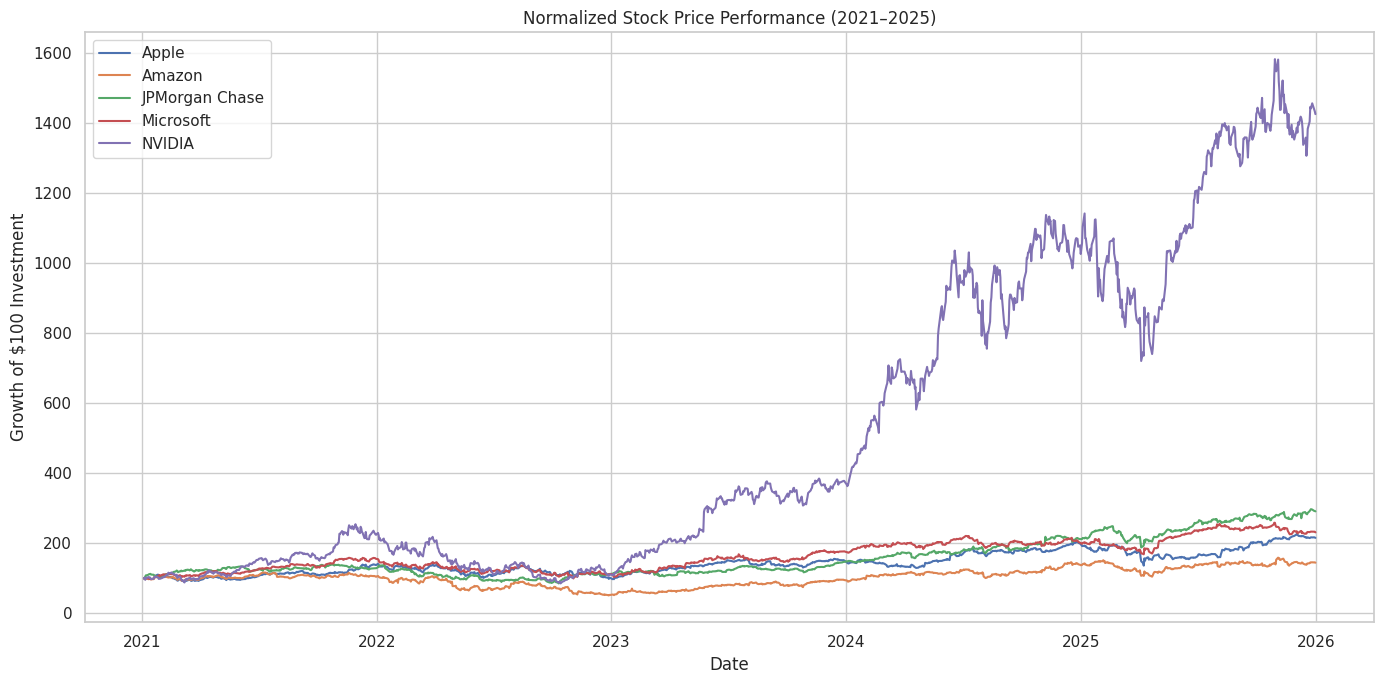

In [10]:
normalized_prices = (prices / prices.iloc[0]) * 100

plt.figure(figsize=(14, 7))

for company in normalized_prices.columns:
    plt.plot(normalized_prices.index, normalized_prices[company], label=company)

plt.title("Normalized Stock Price Performance (2021–2025)")
plt.xlabel("Date")
plt.ylabel("Growth of $100 Investment")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 6.1 Stock Price Performance Findings

The normalized stock performance chart reveals significant differences in historical investment growth across the five companies.

- **NVIDIA** demonstrated the strongest growth, significantly outperforming the other companies, particularly from 2023 onward.
- **JPMorgan Chase** showed consistent long-term growth and finished as the second-strongest performer.
- **Microsoft** and **Apple** experienced moderate growth throughout the research period.
- **Amazon** demonstrated comparatively slower growth and finished with the lowest normalized investment value.

Overall, NVIDIA delivered the strongest historical price performance, although its substantial fluctuations indicate higher investment risk.

### 6.2 Investment Risk Comparison

Annualized volatility is visualized to compare the historical risk levels of the five companies.

A bar chart provides a clear comparison of how much each company's daily stock returns fluctuated during the research period.

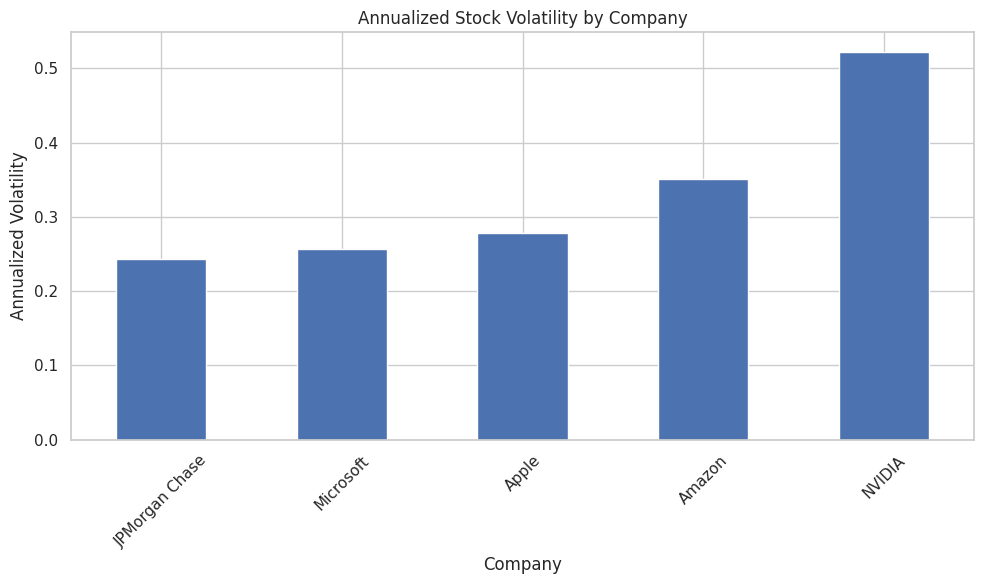

In [11]:
plt.figure(figsize=(10, 6))

annualized_volatility.sort_values().plot(
    kind="bar",
    title="Annualized Stock Volatility by Company"
)

plt.xlabel("Company")
plt.ylabel("Annualized Volatility")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.2.1 Volatility Analysis Findings

The volatility comparison highlights differences in historical investment risk among the selected companies.

NVIDIA recorded the highest annualized volatility at 52.22%, indicating substantially greater fluctuations in daily returns. Amazon followed at 35.11%. In comparison, JPMorgan Chase had the lowest volatility at 24.27%, followed by Microsoft at 25.71% and Apple at 27.86%.

These findings suggest that NVIDIA experienced the greatest historical price variability, while JPMorgan Chase demonstrated the most stable return pattern during the research period.

### 6.3 Risk and Return Comparison

To further evaluate investment performance, annualized returns are compared with annualized volatility.

This analysis helps illustrate the relationship between historical investment returns and risk. Companies with higher returns may also experience greater fluctuations, making it important to consider both measures when evaluating investment performance.

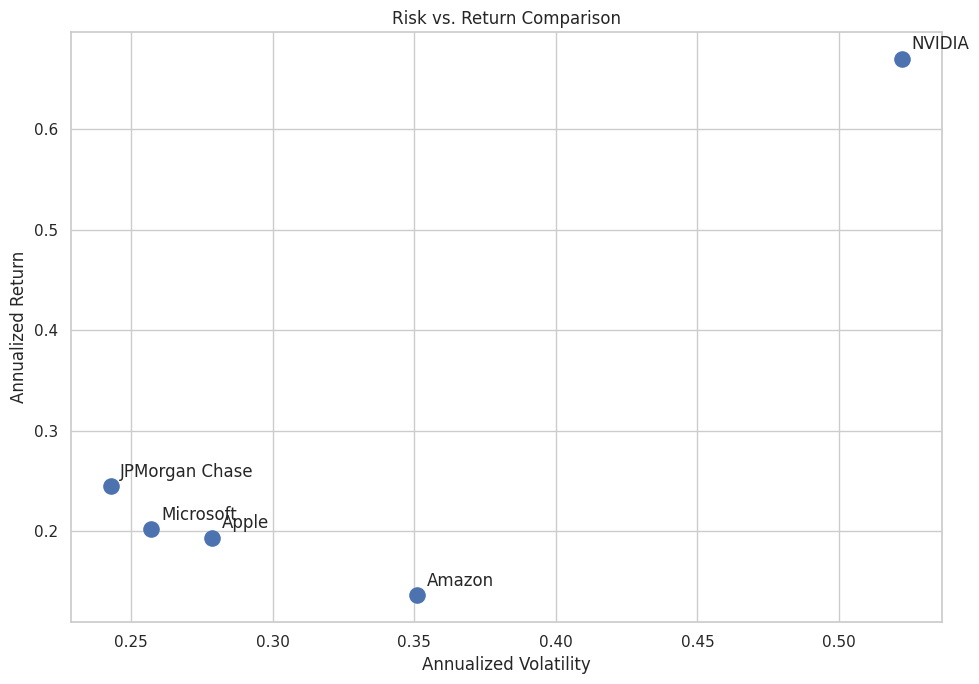

In [12]:
risk_return = pd.DataFrame({
    "Annualized Return": annualized_returns,
    "Annualized Volatility": annualized_volatility
})

plt.figure(figsize=(10, 7))

plt.scatter(
    risk_return["Annualized Volatility"],
    risk_return["Annualized Return"],
    s=120
)

for company in risk_return.index:
    plt.annotate(
        company,
        (
            risk_return.loc[company, "Annualized Volatility"],
            risk_return.loc[company, "Annualized Return"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.title("Risk vs. Return Comparison")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")
plt.grid(True)
plt.tight_layout()
plt.show()

### 6.3.1 Risk and Return Analysis Findings

The risk-return comparison illustrates the relationship between historical investment performance and volatility across the five selected companies.

NVIDIA recorded the highest annualized return at 66.95%, accompanied by the highest volatility at 52.22%. This indicates that its stronger historical performance came with substantially greater fluctuations in daily returns.

JPMorgan Chase demonstrated a different risk-return profile, generating a 24.45% annualized return while recording the lowest volatility at 24.27%. Microsoft and Apple produced moderate returns with relatively similar volatility levels.

Amazon recorded the lowest annualized return at 13.60%, despite having the second-highest volatility at 35.11%.

Overall, the findings demonstrate that higher historical returns do not always correspond to lower investment risk. JPMorgan Chase displayed a comparatively favorable balance between historical returns and volatility, while NVIDIA represented the highest-return, highest-volatility investment among the companies analyzed.

## 7. Summary of Financial Performance

This section consolidates the annualized return and volatility measurements for all five companies.

Comparing these metrics provides an overview of historical investment performance and risk, allowing differences between the companies to be evaluated using consistent financial measures.

In [16]:
summary = pd.DataFrame({
    "Annualized Arithmetic Return (%)": annualized_returns * 100,
    "Annualized Volatility (%)": annualized_volatility * 100
})

summary = summary.sort_values(
   by="Annualized Arithmetic Return (%)",
    ascending=False
)

display(summary.round(2))

,Annualized Arithmetic Return (%),Annualized Volatility (%)
Ticker,,
NVIDIA,66.9500,52.2200
JPMorgan Chase,24.4500,24.2700
Microsoft,20.1700,25.7100
Apple,19.3200,27.8600
Amazon,13.6000,35.1100


## 8. Conclusion

This project analyzed the historical stock market performance of Apple, Amazon, JPMorgan Chase, Microsoft, and NVIDIA over a five-year period from January 2021 through December 2025.

Using Python and financial data analysis techniques, the project evaluated adjusted closing prices, daily returns, annualized arithmetic returns, and annualized volatility. Visualizations were also developed to compare historical investment growth and examine the relationship between risk and return.

The findings revealed that NVIDIA achieved the highest annualized arithmetic return at 66.95%, but also experienced the highest annualized volatility at 52.22%. This indicates that its stronger historical performance was accompanied by greater fluctuations in daily returns. JPMorgan Chase demonstrated the lowest volatility at 24.27%, alongside the second-highest annualized arithmetic return of 24.45%. In comparison, Amazon recorded the lowest annualized arithmetic return at 13.60%, despite having the second-highest volatility at 35.11%.

Overall, the analysis demonstrates the importance of evaluating both investment performance and risk when comparing publicly traded companies. The results highlight how Python can be used to collect, organize, analyze, and visualize historical financial data to generate meaningful insights that support financial analysis and investment research.

### Limitations

This analysis is based on historical stock market data and does not account for transaction costs, taxes, or individual investor circumstances. Annualized arithmetic returns and volatility are calculated using historical daily returns and should not be interpreted as predictions of future performance. Additionally, the analysis focuses on five selected companies and does not represent the entire stock market. The findings are intended for educational and analytical purposes and do not constitute investment advice.